# Trabalho 1 de Aprendizado de Máquina
## Dataset: Seoul Bike Sharing Demand
#### Integrantes: Felipe Pasinato Rossoni, Renan Augusto da Silva Zen, Stefano Fiorioli Dahmer

O dataset contém informações sobre quantas bicicletas foram alugadas por hora na cidade de Seoul (capital da Coreia do Sul), com informações sobre: Data, Hora, Qtd de Bicicletas alugadas, Temperatura, Chuva, Neve, Umidade, Estação, Feriado, entre outros.

O objetivo do modelo será prever, dadas as condições de um determinado dia/hora, quantas bicicletas serão alugadas.

Atributos do dataset:
Date, Rented Bike Count, Hour, Temperature (°C), Humidity (%), Wind speed (m/s), Visibility (10m), Dew point temperature (°C), Solar Radiation (Mj/m²), Rainfall (mm), Snowfall (cm), Seasons, Holiday, Functioning Day.


In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings


## Análise exploratória dos dados
Nessa seção é possível visualizar algumas informações interessantes sobre o dataset. Existem gráficos do total diário de bicicletas alugadas durante o perído em que o dataset fornece informações, média de bicicletas alugadas por hora do dia, quantidade de aluguéis e temperatura do momento do aluguel e frequência de horas por faixa de demanda de bicicletas.

In [2]:
df = pd.read_csv('SeoulBikeData.csv')

# dimensoes e valores ausentes
print("Dimensões do dataset:", df.shape)
print("\nValores ausentes por coluna:")
print(df.isnull().sum())

# descricao dos atributos
display(df.describe().T)

# distribuicao de atributos categóricos
for coluna in ['Seasons', 'Holiday', 'Functioning Day']:
    print(f'\n{coluna}:')
    print(df[coluna].value_counts())


Dimensões do dataset: (8760, 14)

Valores ausentes por coluna:
Date                     0
Rented Bike Count        0
Hour                     0
Temperature              0
Humidity                 0
Wind speed               0
Visibility               0
Dew point temperature    0
Solar Radiation          0
Rainfall                 0
Snowfall                 0
Seasons                  0
Holiday                  0
Functioning Day          0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Rented Bike Count,8760.0,704.602055,644.997468,0.0,191.00,504.50,1065.25,3556.00
Hour,8760.0,11.500000,6.922582,0.0,5.75,11.50,17.25,23.00
Temperature,8760.0,12.882922,11.944825,-17.8,3.50,13.70,22.50,39.40
Humidity,8760.0,58.226256,20.362413,0.0,42.00,57.00,74.00,98.00
Wind speed,8760.0,1.724909,1.036300,0.0,0.90,1.50,2.30,7.40
Visibility,8760.0,1436.825799,608.298712,27.0,940.00,1698.00,2000.00,2000.00
Dew point temperature,8760.0,4.073813,13.060369,-30.6,-4.70,5.10,14.80,27.20
Solar Radiation,8760.0,0.569111,0.868746,0.0,0.00,0.01,0.93,3.52
Rainfall,8760.0,0.148687,1.128193,0.0,0.00,0.00,0.00,35.00
Snowfall,8760.0,0.075068,0.436746,0.0,0.00,0.00,0.00,8.80



Seasons:
Seasons
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64

Holiday:
Holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64

Functioning Day:
Functioning Day
Yes    8465
No      295
Name: count, dtype: int64


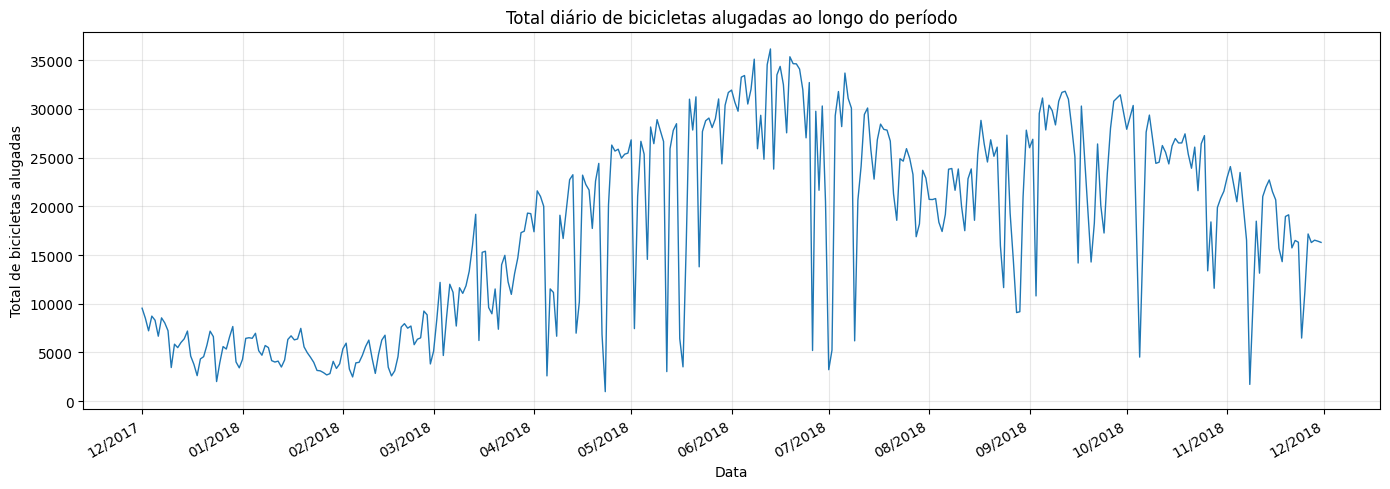

In [3]:
df_eda = df.copy()
df_eda['Date'] = pd.to_datetime(df_eda['Date'], format='%d/%m/%Y')

df_func = df_eda[df_eda['Functioning Day'] == 'Yes'].copy()

alugueis_diarios = (
    df_func.groupby('Date')['Rented Bike Count']
    .sum()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(alugueis_diarios.index, alugueis_diarios.values,
        linewidth=1)

ax.set_title('Total diário de bicicletas alugadas ao longo do período')
ax.set_xlabel('Data')
ax.set_ylabel('Total de bicicletas alugadas')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


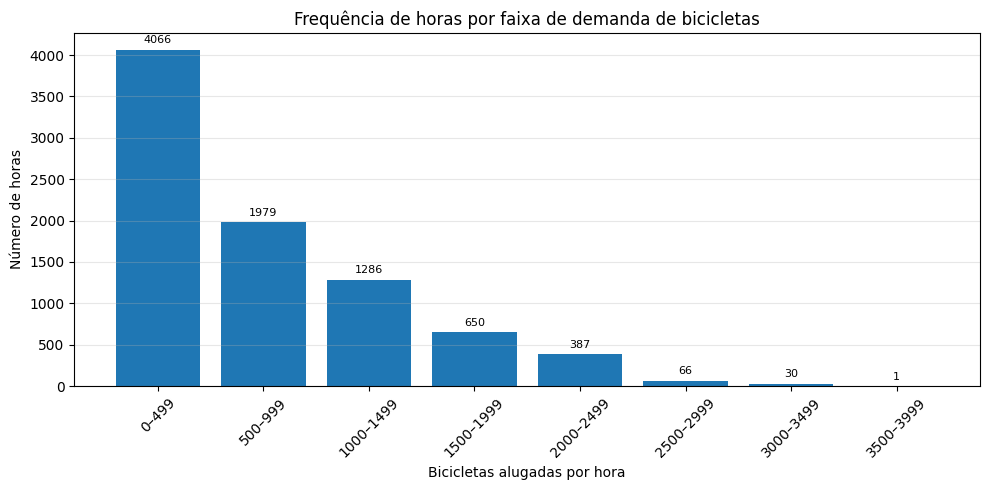

In [4]:
# nesse grafico esta indicado quantas "horas" tiveram tal demanda de bicicletas
# exemplo: tiveram 4066 instancias de horas (seja 8h, 12h, 13h, 19h, 23h) que tiveram demanda de bicicletas entre 0-499
# ou seja, em um dia, as 8h, se a demanda foi entre 0 e 499, esse dado entrou nessa conta dos 4066
alugueis = df_func['Rented Bike Count']

maximo = int(alugueis.max())
limite = (maximo // 500 + 2) * 500
faixas = np.arange(0, limite, 500)
contagens, limites = np.histogram(alugueis, bins=faixas)

rotulos = [
    f'{limites[i]:.0f}–{limites[i+1]-1:.0f}'
    for i in range(len(contagens))
]

plt.figure(figsize=(10, 5))
barras = plt.bar(rotulos, contagens)

plt.bar_label(barras, padding=3, fontsize=8)

plt.title('Frequência de horas por faixa de demanda de bicicletas')
plt.xlabel('Bicicletas alugadas por hora')
plt.ylabel('Número de horas')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


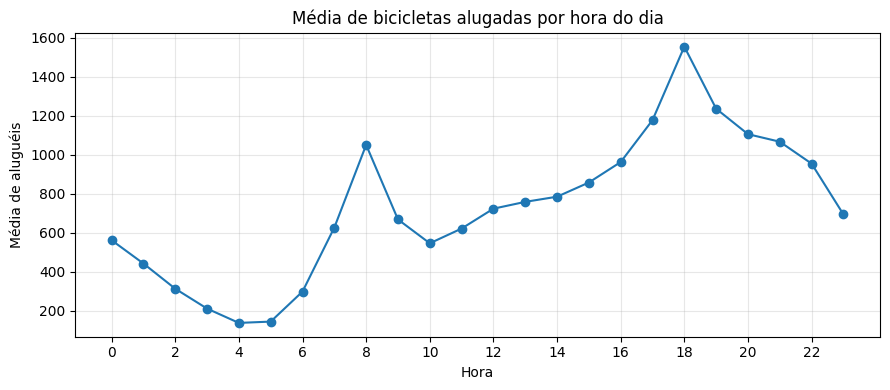

In [5]:
media_hora = df_func.groupby('Hour')['Rented Bike Count'].mean()

plt.figure(figsize=(9, 4))
plt.plot(media_hora.index, media_hora.values, marker='o')

plt.title('Média de bicicletas alugadas por hora do dia')
plt.xlabel('Hora')
plt.ylabel('Média de aluguéis')
plt.xticks(range(0, 24, 2))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


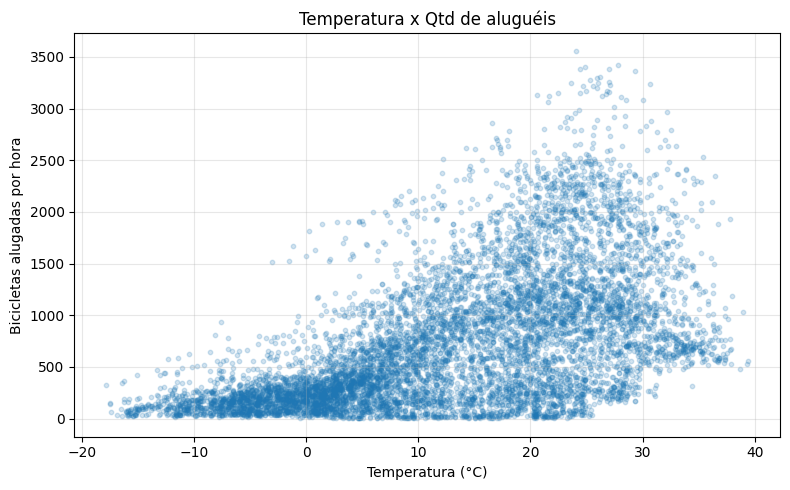

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_func['Temperature'],
    df_func['Rented Bike Count'],
    alpha=0.2,
    s=10
)

plt.title('Temperatura x Qtd de aluguéis')
plt.xlabel('Temperatura (°C)')
plt.ylabel('Bicicletas alugadas por hora')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Pré-processamento

In [7]:
# deixa so dias que functioning day = Yes no dataset (dias com No sempre tem bike count = 0)
df = df[df['Functioning Day'] == 'Yes'].copy()
df = df.drop('Functioning Day', axis=1)

# separa dia e mes pra ver tendencias
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df = df.sort_values(['Date', 'Hour']).reset_index(drop=True)

df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek # 0 = segunda, 6 = domingo
df = df.drop('Date', axis=1)

X = df.drop('Rented Bike Count', axis=1)
y = df['Rented Bike Count']

# separa em treino e teste sem embaralhar (para nao receber informacoes futuras)
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, shuffle=False
)


In [8]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore')) # evita colunas redundantes
])
warnings.filterwarnings('ignore', category=UserWarning)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])



## Modelos e métricas

In [9]:
# validacao cruzada temporal com 5 folds: cada fold treina no passado e valida no periodo seguinte
tscv = TimeSeriesSplit(n_splits=5)

# metricas avaliadas
scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

# modelos do spot-check com hiperparametros padrao
modelos = {
    'Dummy': DummyRegressor(), # baseline: sempre preve a media
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'KNN': KNeighborsRegressor(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': HistGradientBoostingRegressor(random_state=42)
}

## Resultados

In [11]:
resultados = []
rmse_folds = {} # guarda o rmse de cada fold pra usar no grafico

for nome, modelo in modelos.items():
    # preprocessor dentro do pipeline pra ser ajustado so no treino de cada fold (evita data leakage)
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', modelo)])
    cv = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=scoring)

    rmse_folds[nome] = -cv['test_rmse']

    # media e desvio padrao das metricas nos 5 folds
    resultados.append({
        'Modelo': nome,
        'RMSE': f"{-cv['test_rmse'].mean():.2f} ± {cv['test_rmse'].std():.2f}",
        'MAE': f"{-cv['test_mae'].mean():.2f} ± {cv['test_mae'].std():.2f}",
        'R²': f"{cv['test_r2'].mean():.3f} ± {cv['test_r2'].std():.3f}"
    })

df_resultados = pd.DataFrame(resultados)
df_resultados

,Modelo,RMSE,MAE,R²
0,Dummy,676.52 ± 294.68,510.39 ± 226.70,-0.466 ± 0.291
1,Linear Regression,495.16 ± 200.13,393.88 ± 176.15,0.197 ± 0.135
2,Ridge,495.10 ± 200.13,393.82 ± 176.06,0.198 ± 0.136
3,KNN,416.12 ± 149.72,300.44 ± 111.01,0.386 ± 0.147
4,Decision Tree,363.37 ± 135.04,251.54 ± 103.72,0.514 ± 0.122
5,Random Forest,290.55 ± 114.80,205.69 ± 89.13,0.690 ± 0.110
6,Gradient Boosting,283.24 ± 117.80,196.52 ± 88.58,0.688 ± 0.192


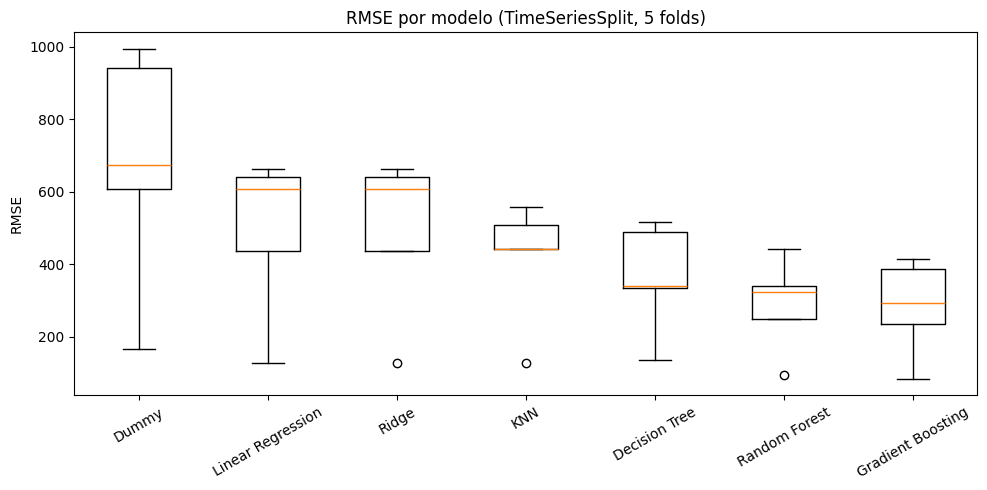

In [12]:
# boxplot do rmse por fold pra comparar os modelos (RMSE mais baixo é melhor)
plt.figure(figsize=(10, 5))
plt.boxplot(list(rmse_folds.values()), tick_labels=list(rmse_folds.keys()))
plt.ylabel('RMSE')
plt.title('RMSE por modelo (TimeSeriesSplit, 5 folds)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Avaliação final no conjunto de teste

In [13]:
# avaliação final dos três modelos mais promissores

modelos_finalistas = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': HistGradientBoostingRegressor(random_state=42),
    'Decision Tree': DecisionTreeRegressor(random_state=42)
}

resultados_teste = []

for nome, modelo in modelos_finalistas.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', modelo)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_valid)

    resultados_teste.append({
        'Modelo': nome,
        'RMSE': np.sqrt(mean_squared_error(y_valid, y_pred)),
        'MAE': mean_absolute_error(y_valid, y_pred),
        'R²': r2_score(y_valid, y_pred)
    })

df_resultados_teste = pd.DataFrame(resultados_teste)

display(df_resultados_teste.round(3))


,Modelo,RMSE,MAE,R²
0,Random Forest,323.736,227.545,0.708
1,Gradient Boosting,288.131,210.406,0.769
2,Decision Tree,410.746,295.569,0.530
